# Final Model Comparison

This notebook compares all trained models using the saved result files in:

`_03_Models/results/`

All experiments reuse the same training and held-out test split and the same original feature definitions.

Hyperparameter search budgets, class weighting, and model-specific procedures differ between experiments. The SVM experiment includes probability calibration.

The ranking describes performance on this shared test split.
Interpret it within the dataset and evaluated configurations.

This notebook reads saved results without retraining any model.

## 1. Import libraries and locate project folders

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Locate project root robustly.
cwd = Path.cwd()
PROJECT_ROOT = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "_03_Models" / "results").exists() and (candidate / "data").exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root. Run this notebook from inside the project folder.")

RESULTS_DIR = PROJECT_ROOT / "_03_Models" / "results"
RESULTS_DIR

WindowsPath('d:/NU/semester_8/data_mining/project/phase I/_03_Models/results')

## 2. Load saved results for all 11 models

The notebook requires one summary result file for each model.

Each file must contain exactly one row and the required evaluation metrics. Metric values must be numeric and between zero and one.

Model display names are standardized when building the comparison.
Previous comparison outputs are not loaded as model results.

In [2]:
EXPECTED_RESULTS = {
    "logistic_regression_results.csv": "Logistic Regression",
    "naive_bayes_results.csv": "Naive Bayes",
    "decision_tree_results.csv": "Decision Tree",
    "random_forest_results.csv": "Random Forest",
    "gradient_boosting_results.csv": "Gradient Boosting",
    "xgboost_results.csv": "XGBoost",
    "lightgbm_results.csv": "LightGBM",
    "catboost_results.csv": "CatBoost",
    "knn_results.csv": "KNN",
    "svm_results.csv": "SVM",
    "mlp_results.csv": "MLP",
}

missing_results = [
    filename
    for filename in EXPECTED_RESULTS
    if not (RESULTS_DIR / filename).is_file()
]

if missing_results:
    raise FileNotFoundError(
        "Missing model result files:\n"
        + "\n".join(missing_results)
        + f"\nExpected folder: {RESULTS_DIR}"
    )

print(f"Found all {len(EXPECTED_RESULTS)} required result files.")

for filename in EXPECTED_RESULTS:
    print("-", filename)

Found all 11 required result files.
- logistic_regression_results.csv
- naive_bayes_results.csv
- decision_tree_results.csv
- random_forest_results.csv
- gradient_boosting_results.csv
- xgboost_results.csv
- lightgbm_results.csv
- catboost_results.csv
- knn_results.csv
- svm_results.csv
- mlp_results.csv


In [3]:
preferred_columns = [
    "model",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1",
    "roc_auc_ovr_macro",
    "roc_auc_ovr_weighted",
    "dropout_precision",
    "dropout_recall",
    "dropout_f1",
]

metric_columns = preferred_columns[1:]
rows = []

for filename, display_name in EXPECTED_RESULTS.items():
    path = RESULTS_DIR / filename
    frame = pd.read_csv(path)

    if len(frame) != 1:
        raise ValueError(
            f"{filename} must contain exactly one result row. "
            f"Found: {len(frame)}"
        )

    missing_columns = [
        column
        for column in preferred_columns
        if column not in frame.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{filename} is missing columns: {missing_columns}"
        )

    row = frame.loc[:, preferred_columns].iloc[0].copy()

    observed_name = str(row["model"]).strip()

    if observed_name.casefold() != display_name.casefold():
        raise ValueError(
            f"Unexpected model name in {filename}: "
            f"{observed_name!r}. Expected {display_name!r}."
        )

    row["model"] = display_name

    for metric in metric_columns:
        value = pd.to_numeric(row[metric], errors="raise")

        if pd.isna(value) or not 0 <= value <= 1:
            raise ValueError(
                f"Invalid {metric} in {filename}: {value}"
            )

        row[metric] = float(value)

    rows.append(row.to_dict())

comparison_df = pd.DataFrame(
    rows,
    columns=preferred_columns,
)

print("Models compared:", len(comparison_df))
display(comparison_df)

Models compared: 11


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro,roc_auc_ovr_weighted,dropout_precision,dropout_recall,dropout_f1
0,Logistic Regression,0.767232,0.736920,0.729085,0.774978,0.893009,0.907999,0.853755,0.760563,0.804469
1,Naive Bayes,0.237288,0.378763,0.212249,0.166023,0.671601,0.697270,0.544554,0.193662,0.285714
2,Decision Tree,0.691525,0.681273,0.665674,0.712868,0.841779,0.864543,0.864253,0.672535,0.756436
3,Random Forest,0.779661,0.736407,0.735134,0.782451,0.901359,0.915415,0.847390,0.742958,0.791745
4,Gradient Boosting,0.779661,0.696894,0.707274,0.769098,0.897114,0.912810,0.830769,0.760563,0.794118
5,XGBoost,0.805650,0.729676,0.743169,0.796164,0.906263,0.919295,0.845283,0.788732,0.816029
6,LightGBM,0.798870,0.726829,0.737038,0.790551,0.900472,0.914073,0.817204,0.802817,0.809947
7,CatBoost,0.790960,0.707372,0.718723,0.779366,0.900936,0.915777,0.838346,0.785211,0.810909
8,KNN,0.732203,0.613203,0.619353,0.703960,0.840460,0.865405,0.835556,0.661972,0.738703
9,SVM,0.800000,0.744445,0.750933,0.798209,0.883448,0.902324,0.875000,0.764085,0.815789


## 3. Rank models

Models are ranked by held-out test Macro-F1.

Macro-F1 gives equal weight to the three outcome classes.
Balanced Accuracy and Dropout Recall are used as tie-breakers.

Dropout Recall is interpreted alongside Dropout Precision to account for both missed dropout cases and false dropout alerts.

This is a descriptive ranking for the evaluated experiments.

In [4]:
ranking_df = comparison_df.sort_values(
    by=["macro_f1", "balanced_accuracy", "dropout_recall"],
    ascending=False,
).reset_index(drop=True)

ranking_df.insert(0, "rank_by_macro_f1", range(1, len(ranking_df) + 1))
ranking_df

,rank_by_macro_f1,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro,roc_auc_ovr_weighted,dropout_precision,dropout_recall,dropout_f1
0,1,SVM,0.800000,0.744445,0.750933,0.798209,0.883448,0.902324,0.875000,0.764085,0.815789
1,2,XGBoost,0.805650,0.729676,0.743169,0.796164,0.906263,0.919295,0.845283,0.788732,0.816029
2,3,LightGBM,0.798870,0.726829,0.737038,0.790551,0.900472,0.914073,0.817204,0.802817,0.809947
3,4,Random Forest,0.779661,0.736407,0.735134,0.782451,0.901359,0.915415,0.847390,0.742958,0.791745
4,5,Logistic Regression,0.767232,0.736920,0.729085,0.774978,0.893009,0.907999,0.853755,0.760563,0.804469
5,6,CatBoost,0.790960,0.707372,0.718723,0.779366,0.900936,0.915777,0.838346,0.785211,0.810909
6,7,Gradient Boosting,0.779661,0.696894,0.707274,0.769098,0.897114,0.912810,0.830769,0.760563,0.794118
7,8,MLP,0.729944,0.664131,0.665938,0.726336,0.853724,0.870261,0.753472,0.764085,0.758741
8,9,Decision Tree,0.691525,0.681273,0.665674,0.712868,0.841779,0.864543,0.864253,0.672535,0.756436
9,10,KNN,0.732203,0.613203,0.619353,0.703960,0.840460,0.865405,0.835556,0.661972,0.738703


## 4. Save comparison outputs

In [5]:
comparison_df.to_csv(RESULTS_DIR / "final_model_comparison_results.csv", index=False)
ranking_df.to_csv(RESULTS_DIR / "final_model_ranking_by_macro_f1.csv", index=False)

print("Saved:")
print(RESULTS_DIR / "final_model_comparison_results.csv")
print(RESULTS_DIR / "final_model_ranking_by_macro_f1.csv")

Saved:
d:\NU\semester_8\data_mining\project\phase I\_03_Models\results\final_model_comparison_results.csv
d:\NU\semester_8\data_mining\project\phase I\_03_Models\results\final_model_ranking_by_macro_f1.csv


## 5. Metric comparison charts

These charts are presentation-friendly and can be rerun after adding more models.

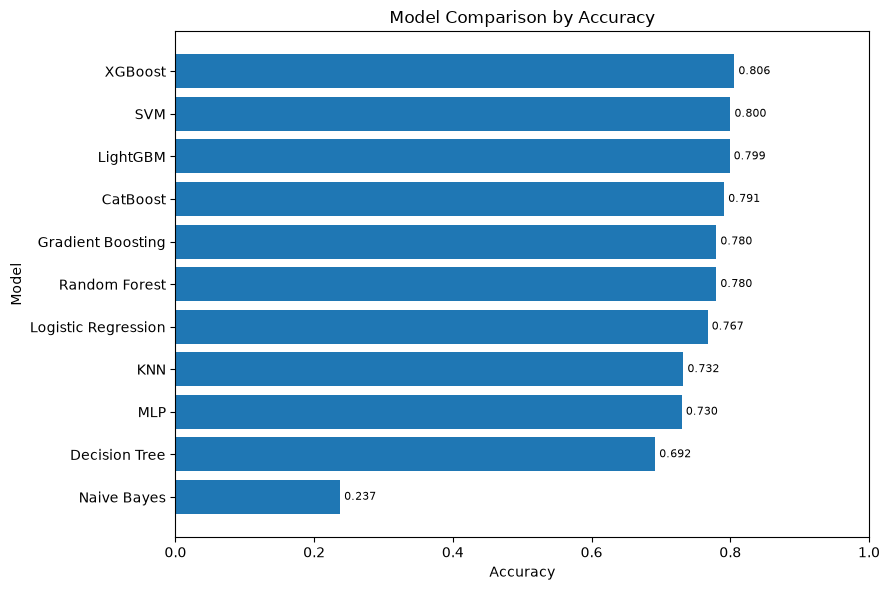

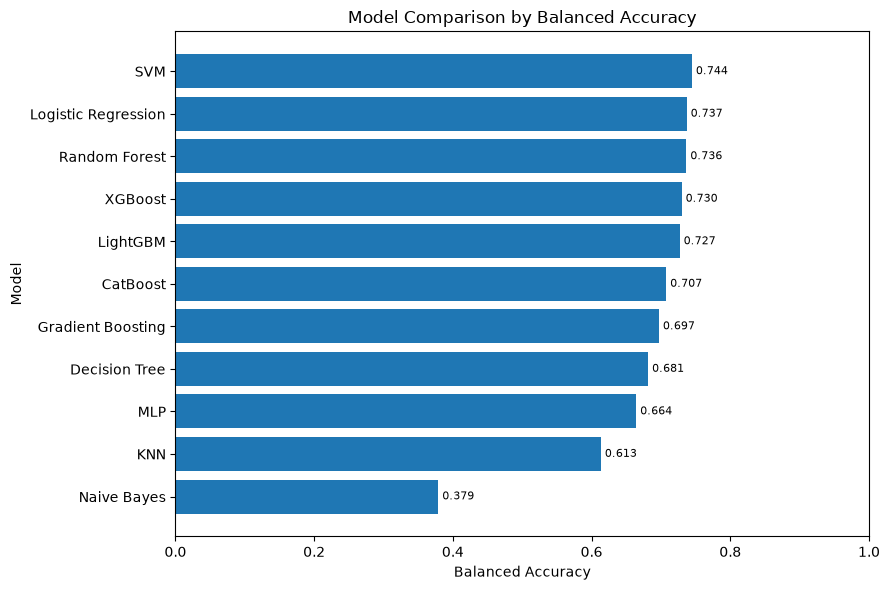

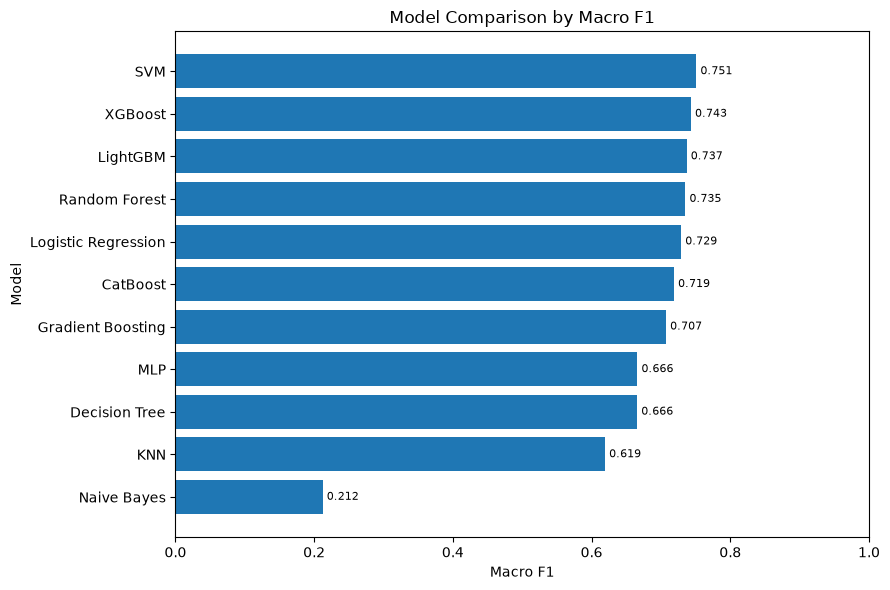

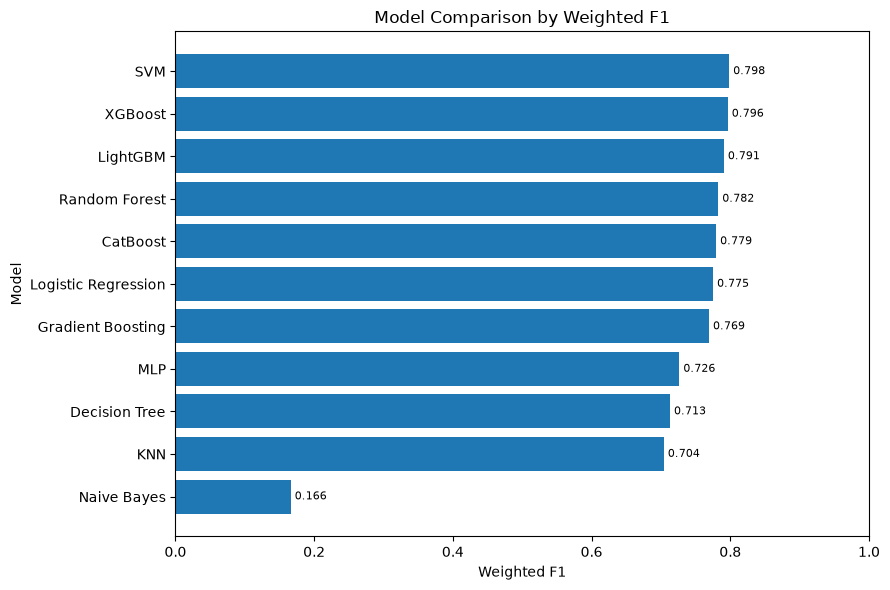

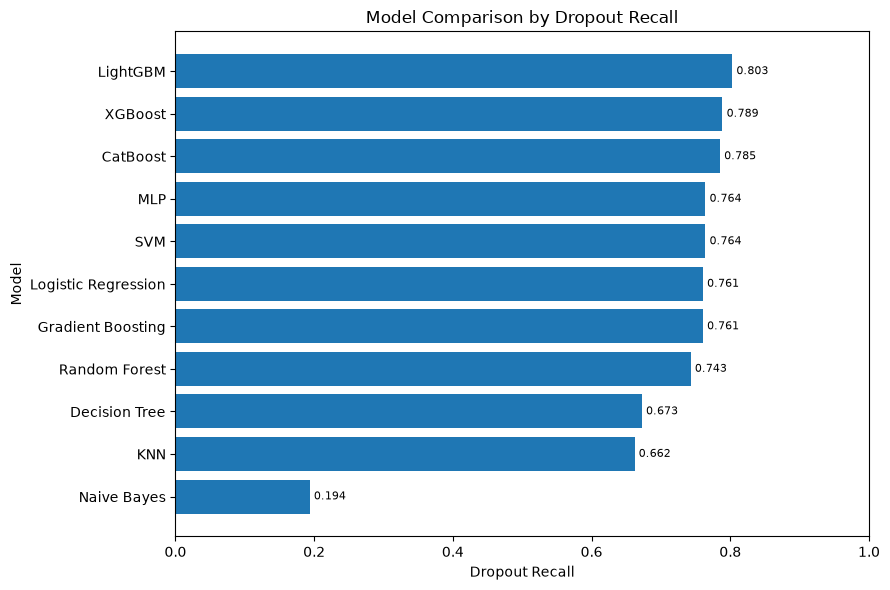

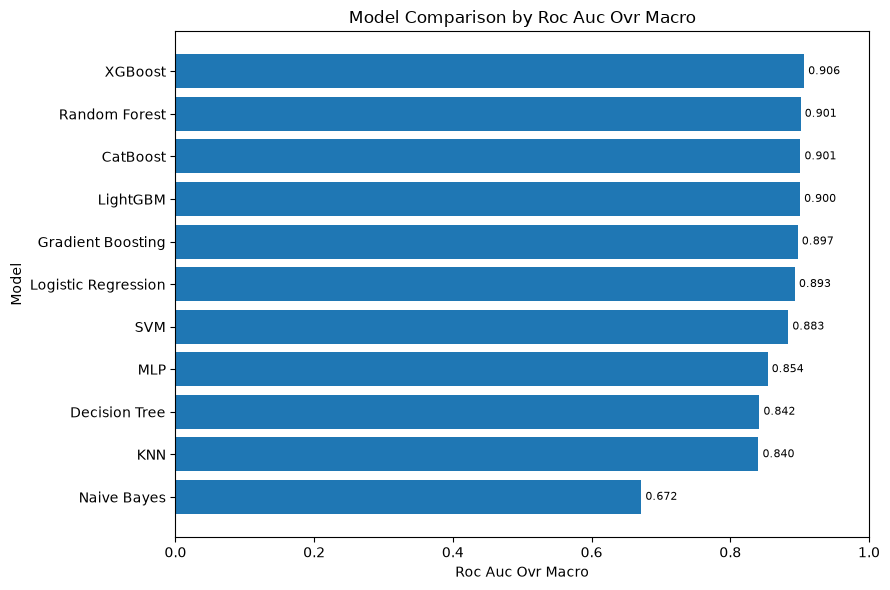

In [6]:
metrics_to_plot = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1",
    "dropout_recall",
    "roc_auc_ovr_macro",
]

for metric in metrics_to_plot:
    plot_df = comparison_df.sort_values(
        metric,
        ascending=True,
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    bars = ax.barh(
        plot_df["model"],
        plot_df[metric],
    )

    metric_label = metric.replace("_", " ").title()

    ax.set_title(f"Model Comparison by {metric_label}")
    ax.set_xlabel(metric_label)
    ax.set_ylabel("Model")
    ax.set_xlim(0, 1)

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8,
    )

    fig.tight_layout()
    plt.show()

## 6. Results summary

All 11 experiments are included in the comparison.

The highest-scoring model can differ across metrics.
Review Macro-F1, Accuracy, Balanced Accuracy, and Dropout Recall together with class-level precision and recall.

The ranking reflects one shared held-out test split and the evaluated model configurations.

The input features include first- and second-semester academic records.
These results describe academic outcome prediction using those records.

In [7]:
summary_metrics = {
    "macro_f1": "Highest test Macro-F1",
    "accuracy": "Highest test Accuracy",
    "balanced_accuracy": "Highest test Balanced Accuracy",
    "dropout_recall": "Highest test Dropout Recall",
}

for metric, description in summary_metrics.items():
    leader = comparison_df.loc[
        comparison_df[metric].idxmax()
    ]

    print(
        f"{description}: "
        f"{leader['model']} "
        f"({leader[metric]:.4f})"
    )

Highest test Macro-F1: SVM (0.7509)
Highest test Accuracy: XGBoost (0.8056)
Highest test Balanced Accuracy: SVM (0.7444)
Highest test Dropout Recall: LightGBM (0.8028)
